# Exploratory Data Analysis on Retail Sales Data

## Objective
The objective of this project is to perform exploratory data analysis on retail sales data to identify sales trends,customer behaviour,product performance, and actionable business insights.

### Tools Used
- Python
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook

In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("All libraries are working!")

All libraries are working!


## 1.Data Loading and Initial Inspection
Checking shape, column, dtypes, null values.

In [86]:
df=pd.read_csv(r"C:\Users\hemas\OneDrive\Desktop\Python\retail_sales.csv")

In [87]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Product Name,Quantity,Price per Unit,Total Amount
0,T103877,2023-01-01,1664,Female,39.0,Grocery,Snacks,5,31.68,158.40
1,T104030,2023-01-01,1137,Male,31.0,Books,Novel,3,37.36,112.08
2,T103852,2023-01-01,1116,Female,46.0,Sports,Yoga Mat,1,39.82,39.82
3,T100594,2023-01-01,1676,Female,39.0,Toys,Building Blocks,2,98.95,197.90
4,T100445,2023-01-02,1190,Female,43.0,Home & Kitchen,Cookware Set,4,48.95,195.80


In [88]:
df.shape

(5000, 10)

In [89]:
df.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Product Name', 'Quantity', 'Price per Unit',
       'Total Amount'],
      dtype='str')

In [90]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    5000 non-null   str    
 1   Date              5000 non-null   str    
 2   Customer ID       5000 non-null   int64  
 3   Gender            4990 non-null   str    
 4   Age               4990 non-null   float64
 5   Product Category  5000 non-null   str    
 6   Product Name      5000 non-null   str    
 7   Quantity          5000 non-null   int64  
 8   Price per Unit    5000 non-null   float64
 9   Total Amount      5000 non-null   float64
dtypes: float64(3), int64(2), str(5)
memory usage: 390.8 KB


In [91]:
df.isnull().sum()

Transaction ID       0
Date                 0
Customer ID          0
Gender              10
Age                 10
Product Category     0
Product Name         0
Quantity             0
Price per Unit       0
Total Amount         0
dtype: int64

## 2.Data Cleaning
The dataset was checked for missing values,duplicate records, and appropriate data types. Missing values is numerical and categorical columns were handled using median and mode imputation respectively.

In [92]:
df.dtypes

Transaction ID          str
Date                    str
Customer ID           int64
Gender                  str
Age                 float64
Product Category        str
Product Name            str
Quantity              int64
Price per Unit      float64
Total Amount        float64
dtype: object

In [93]:
df.duplicated().sum()

np.int64(0)

In [94]:
df.isnull().sum()

Transaction ID       0
Date                 0
Customer ID          0
Gender              10
Age                 10
Product Category     0
Product Name         0
Quantity             0
Price per Unit       0
Total Amount         0
dtype: int64

In [95]:
df['Age'] = df['Age'].fillna(df['Age'].median())

In [96]:
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])

In [97]:
df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Product Name        0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

In [98]:
df.duplicated().sum()

np.int64(0)

## 3.Descriptive Statistics
Descriptive statistics are used to understand the central tendency and variability of the numerical variables in the dataset.

In [99]:
numeric = df.select_dtypes(include='number')

In [100]:
numeric.columns

Index(['Customer ID', 'Age', 'Quantity', 'Price per Unit', 'Total Amount'], dtype='str')

In [101]:
statistics = pd.DataFrame({
    'Mean':numeric.mean(),
    'Median':numeric.median(),
    'Mode':numeric.mode().iloc[0],
    'Standard Deviation':numeric.std()
})
statistics

,Mean,Median,Mode,Standard Deviation
Customer ID,1401.834600,1403.000,1776.00,231.382331
Age,35.733800,35.000,18.00,11.231730
Quantity,2.068400,2.000,1.00,1.150298
Price per Unit,192.247520,96.315,26.82,257.125314
Total Amount,398.791386,171.375,17.69,654.739821


## 4.Time Series Analysis


In [102]:
df['Date'] = pd.to_datetime(df['Date'])

In [103]:
df.dtypes

Transaction ID                 str
Date                datetime64[us]
Customer ID                  int64
Gender                         str
Age                        float64
Product Category               str
Product Name                   str
Quantity                     int64
Price per Unit             float64
Total Amount               float64
dtype: object

### Monthly sales analysis

In [104]:
df['Month'] = df['Date'].dt.to_period('M')

In [105]:
monthly_sales = df.groupby('Month')['Total Amount'].sum()

In [106]:
monthly_sales

Month
2023-01     86321.97
2023-02     56018.04
2023-03     98423.05
2023-04    103092.58
2023-05     80329.84
2023-06     67920.67
2023-07     82767.19
2023-08     84983.64
2023-09     76120.67
2023-10     80553.24
2023-11     76361.74
2023-12     93556.42
2024-01     86804.70
2024-02     94952.93
2024-03     89188.68
2024-04     84636.20
2024-05    112836.81
2024-06     74186.74
2024-07     62668.73
2024-08     83371.11
2024-09     79658.30
2024-10     78627.47
2024-11     70531.79
2024-12     90044.42
Freq: M, Name: Total Amount, dtype: float64

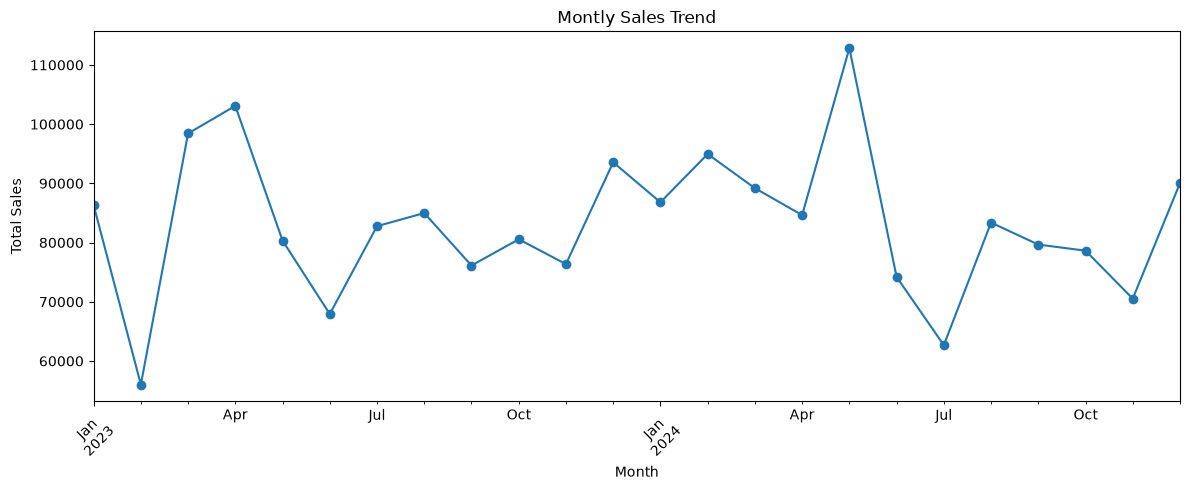

In [107]:
plt.figure(figsize=(12,5))
monthly_sales.plot(kind='line',marker='o')
plt.title('Montly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Observation
The Monthly sales trend shows fluctuations in sales across the analyzed period.

In 2023,
The highest sales were recorded in April, while the lowest sales were recorded in February.

In 2024,
The highest sales were reocrder in May, while the lowext sales were recorded in July.

### Quaterly Sales Analysis

In [108]:
df['Quarter'] = df['Date'].dt.to_period('Q')

In [109]:
quarterly_sales = df.groupby('Quarter')['Total Amount'].sum()

In [110]:
quarterly_sales

Quarter
2023Q1    240763.06
2023Q2    251343.09
2023Q3    243871.50
2023Q4    250471.40
2024Q1    270946.31
2024Q2    271659.75
2024Q3    225698.14
2024Q4    239203.68
Freq: Q-DEC, Name: Total Amount, dtype: float64

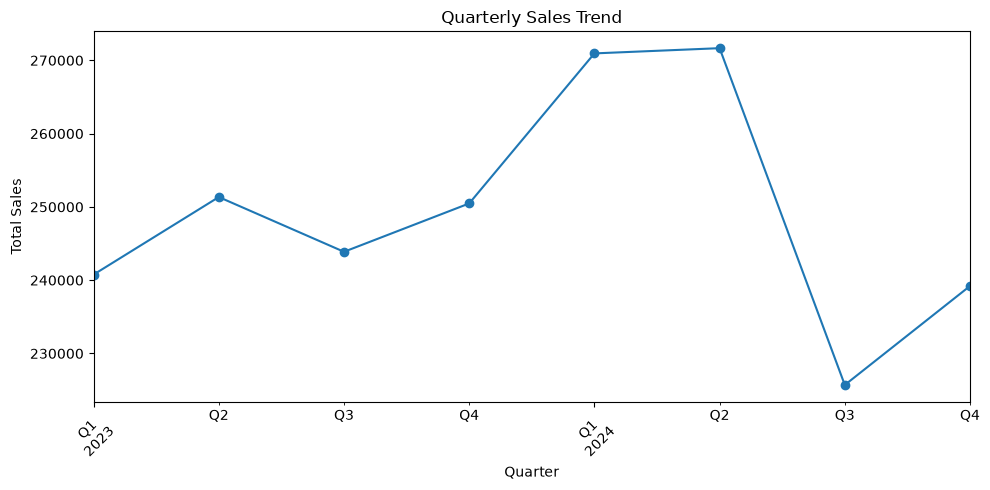

In [111]:
plt.figure(figsize=(10,5))
quarterly_sales.plot(kind='line',marker='o')
plt.title('Quarterly Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Observation
The quarterly sales trend shows how to total sales changed across different quarters.

In 2023, The highest sales were recorded in Second quarter, while the lowest sales were recorded in First quarter.

In 2024, The highest sales were recorded in Second quarter, while the lowest sales were reocrded in Third quarter.

## 5.Customer demographics analysis

### Age Group Distribution

In [112]:
print("Min Age:",df['Age'].min())
print("Max Age:",df['Age'].max())

Min Age: 18.0
Max Age: 75.0


In [113]:
bins = [17,30,45,60,100]
labels = ['18-30','31-45','46-60','60+']
df['Age Group'] = pd.cut(df['Age'],bins=bins,labels=labels)

In [114]:
df['Age Group'].value_counts().sort_index()

Age Group
18-30    1723
31-45    2273
46-60     916
60+        88
Name: count, dtype: int64

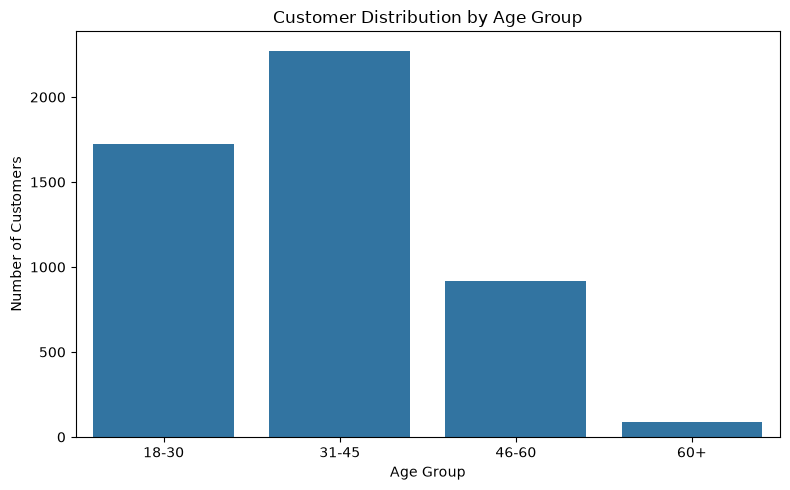

In [115]:
plt.figure(figsize=(8,5))
sns.countplot(
    data=df,
    x='Age Group',
    order=labels)
plt.title('Customer Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

#### Observation
The Age Group distribution shows the number of customers in each age segment.

The 31-45 age group has the highest number of customers, while the 60+ age group has the lowest.

### Gender Breakdown

In [116]:
df['Gender'].value_counts()

Gender
Female    2584
Male      2416
Name: count, dtype: int64

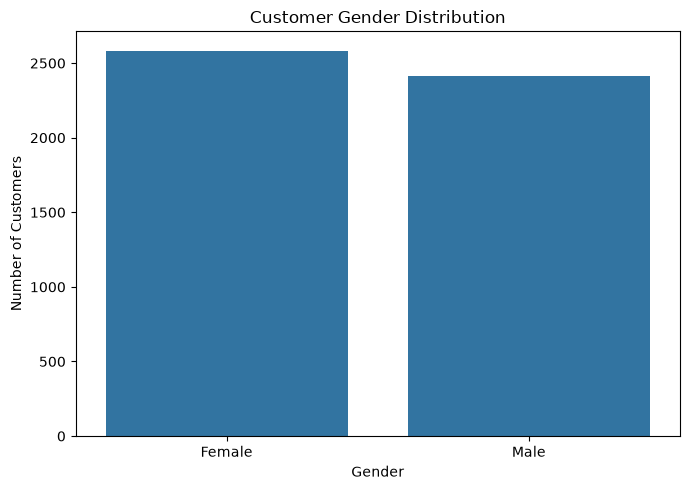

In [117]:
plt.figure(figsize=(7,5))
sns.countplot(data=df,x='Gender')
plt.title('Customer Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()

#### Observation
The gender distribution shows the composition of the customer base.

The Female group has the slightly higher representation than the Male group.

## 6.Product Analysis

### Top 10 best selling products

In [118]:
top_products = (
    df.groupby('Product Name')['Quantity'].sum().sort_values(ascending=False).head(10)
)
top_products

Product Name
Bluetooth Speaker      439
Sneakers               414
Wireless Headphones    411
Dress                  394
Blender                361
Smartphone             360
Jacket                 359
Smartwatch             356
Laptop                 348
T-Shirt                343
Name: Quantity, dtype: int64

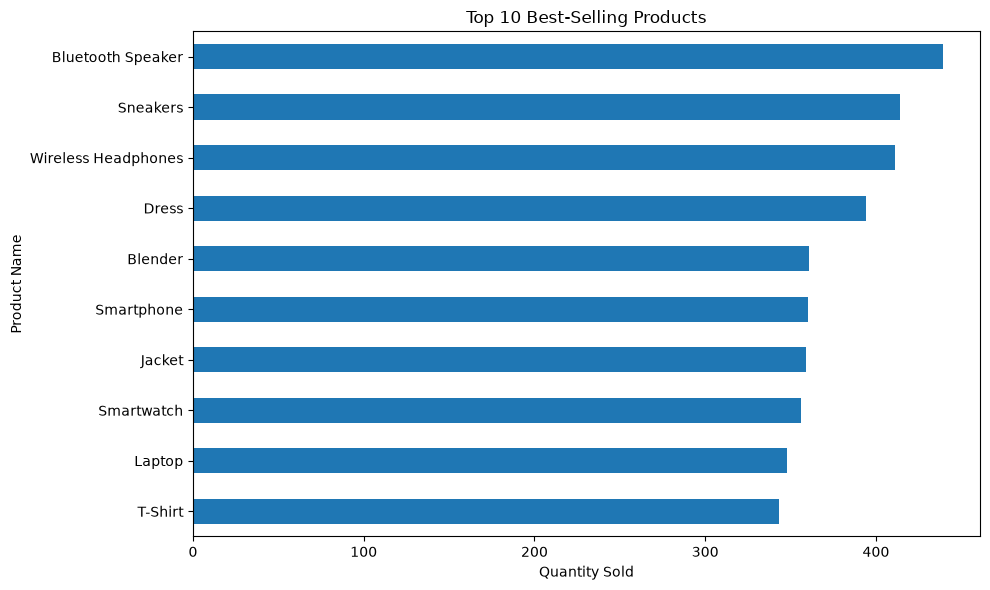

In [119]:
plt.figure(figsize=(10,6))
top_products.sort_values().plot(kind='barh')
plt.title('Top 10 Best-Selling Products')
plt.xlabel('Quantity Sold')
plt.ylabel('Product Name')
plt.tight_layout()
plt.show()

#### Observation
The Top 10 best-selling products were identified based on total quantity sold.

The product Bluetooth Speaker had the highest sales volume, while T-Shirt had the lowest among the Top 10 products.

### Revenue by Product Category

In [120]:
category_revenue = (
    df.groupby('Product Category')['Total Amount'].sum().sort_values(ascending=False))
category_revenue

Product Category
Electronics       1182291.00
Home & Kitchen     274283.63
Clothing           184402.25
Sports             130853.51
Beauty              81363.12
Toys                65770.21
Books               43647.15
Grocery             31346.06
Name: Total Amount, dtype: float64

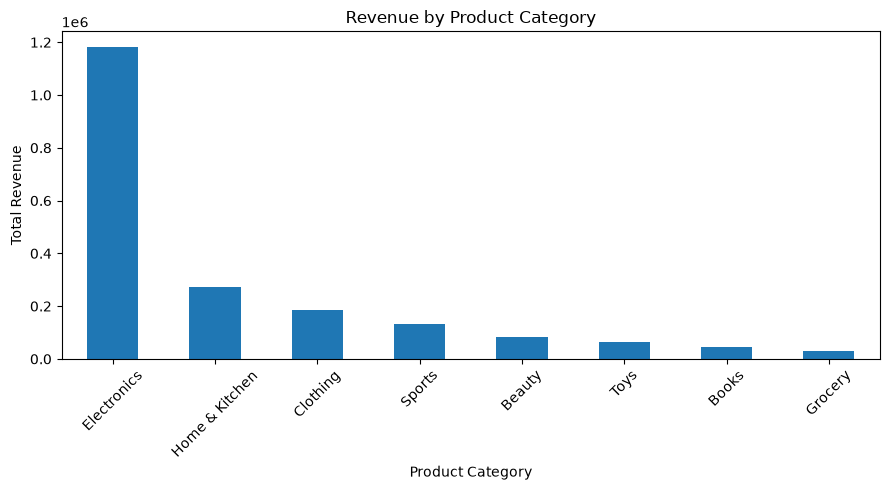

In [121]:
plt.figure(figsize=(9,5))
category_revenue.plot(kind='bar')
plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Observation
Revenue varies across product categories. 

The Electronics category generated the highest revenue, while the Grocery category generated the lowest revenue.

## 7.Correlation Analysis
Correlation matrix between numerical variables.

In [122]:
correlation_data = df[['Age','Quantity','Price per Unit','Total Amount']]

In [123]:
correlation_matrix = correlation_data.corr()
correlation_matrix

,Age,Quantity,Price per Unit,Total Amount
Age,1.000000,-0.009150,-0.027613,-0.022478
Quantity,-0.009150,1.000000,0.003877,0.348698
Price per Unit,-0.027613,0.003877,1.000000,0.817447
Total Amount,-0.022478,0.348698,0.817447,1.000000


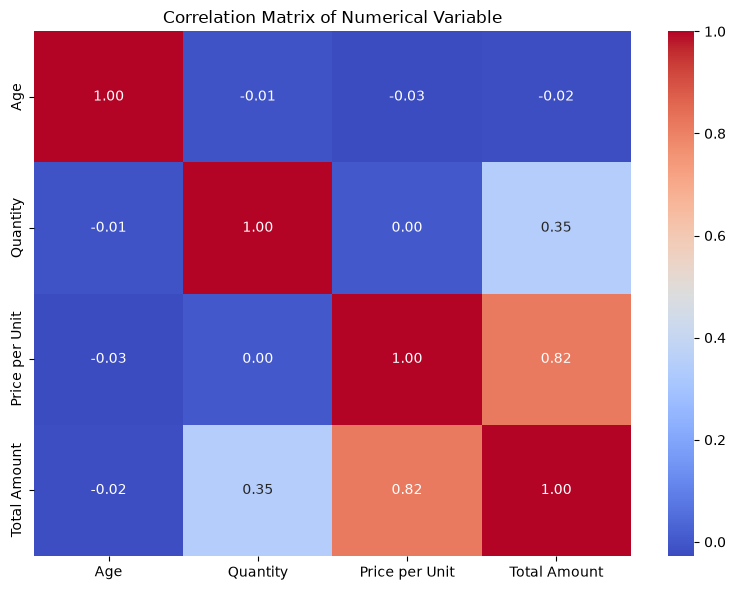

In [124]:
plt.figure(figsize=(8,6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f')
plt.title('Correlation Matrix of Numerical Variable')
plt.tight_layout()
plt.show()

#### Observation
The correlation heatmap shows the relationships between Age, Quantity, Price per Unit, and Total Amount. 

Price per Unit and Total amont have the strongest positive correlation(0.82), indicating that higher-priced items generally contribute to higher transaction amounts.

Quantity and Total amount show a moderate positive correlation (0.35), while Age has very weak correlation with the other numerical variable.

## 8.Average Spending by Age Group (Additional)

In [125]:
avg_spending_age = (
    df.groupby('Age Group',observed=True)['Total Amount'].mean()
)
avg_spending_age

Age Group
18-30    420.220348
31-45    394.909015
46-60    370.642020
60+      372.511250
Name: Total Amount, dtype: float64

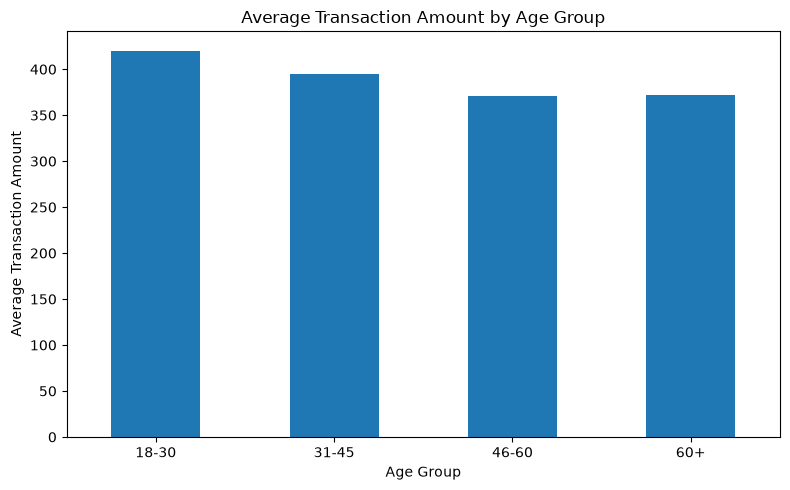

In [126]:
plt.figure(figsize=(8,5))
avg_spending_age.plot(kind='bar')
plt.title('Average Transaction Amount by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Transaction Amount')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Observation
The Average Transaction amount differs across age groups.

The 18-30 age group has the highest average transaction amount, while the 60+ age group has the lowest.

This indicates that the age group with the largest customer population may not necessarily be the highest-spending segment.

# Conclusion

### Key Findings

1. Monthly and quarterly sales showed fluctuations over the analyzed period.
2. The customer base is distributed across different age groups and gender.
3. The top-selling products contribute significantly to overall sale volume.
4. Product categories generate different levels of revenue.
5. Price per Unit has a strong positive correlation revenue with Totla Amount(0.82).
6. Quantity has a moderate positvie correlation with Total Amount (0.35).
7. Customer age has very weak relationships with sales-related variables.

## Business Recommendations

### 1.Focus on High-Revenue Product Categories
The Business should Prioritize high-performing product categories by maintaining sufficient inventory and using targeted promotions to maximum revenue.
### 2.Promote Best-Selling Products
Best-selling products should be kept consistently available.
Bundle offers and cross-selling strategies can be used to increase the average transaction values.
### 3.Use Age-Based Marketing
Marketing campaigns can be tailored to different age groups based on their average transaction value.
Higher-spending groups can receive premium offers, while lower-spending groups can be targeted with discount or product bundles
### 4.Optimixe Product Pricing
Since Price per Unit has a strong positive relationship with Total Amount, the business should analyze pricing carefully and identify products where premium pricing can increase revenue without reducing demand.